### Part 3.1 Impute missing values before model fitting

In [23]:
def fill_train_test_na (train, test, col, type):

    if type == "mode":
        value = train[col].mode()[0]
    elif type == "median":
        value = train[col].median()
    
    train[col] = train[col].fillna(value)
    test[col] = test[col].fillna(value)

In [24]:
# Fill wellbeing and government evaluation levels with mode for missing data
fill_train_test_na(X_train, X_test, "PHQ4_1", "mode")
fill_train_test_na(X_train, X_test, "PHQ4_3", "mode")
fill_train_test_na(X_train, X_test, "WCRex1", "mode")

# Fill household related information with median
fill_train_test_na(X_train, X_test, "household_size", "median")
fill_train_test_na(X_train, X_test, "household_children", "median")

### Part 3.2 KNN model and Hyperparameter Tuning
We tune the model on both $k$ and voting method (uniform or distance).

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import GridSearchCV 
from sklearn.neighbors import KNeighborsClassifier

seed = 5
scoring = "neg_mean_squared_error"
num_folds = 10

scaler = StandardScaler().fit(X_train)
rescaledX_train = scaler.transform(X_train)
model = KNeighborsClassifier()
kfold = KFold(n_splits=num_folds, shuffle=True, random_state=seed)
param_grid = {
    "n_neighbors" : np.arange(1, 20),
    "weights" : ["uniform", "distance"]
}

grid = GridSearchCV(model, param_grid=param_grid, scoring=scoring, cv=kfold)
grid_result = grid.fit(rescaledX_train, y_train)

In [26]:
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: -0.200464 using {'n_neighbors': np.int64(14), 'weights': 'distance'}


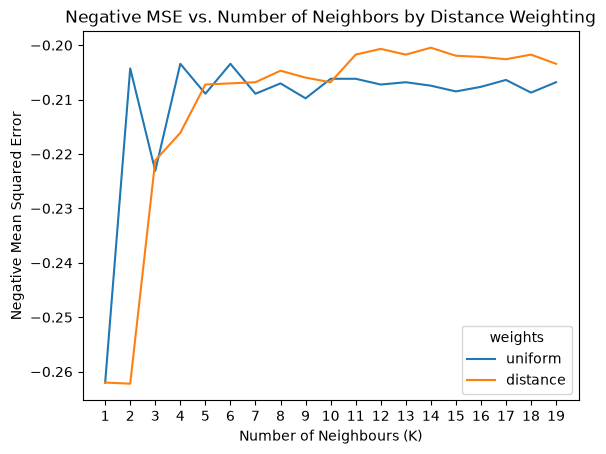

In [27]:
grid_df = pd.DataFrame(grid_result.cv_results_["params"])
grid_df["mean_test_score"] = grid_result.cv_results_["mean_test_score"]

sns.lineplot(
    data=grid_df,
    x="n_neighbors",
    y="mean_test_score",
    hue="weights"
)

plt.xticks(np.arange(1,20))
plt.xlabel('Number of Neighbours (K)')
plt.ylabel('Negative Mean Squared Error')
plt.title('Negative MSE vs. Number of Neighbors by Distance Weighting')
plt.show()

The best model with the lowest MSE has parameters $k=14$ and weight function "distance".

In [28]:
best_model = KNeighborsClassifier(**grid_result.best_params_)
cv_results = cross_val_score(best_model, X_train, y_train, cv=kfold, scoring=scoring)
print("CV MSE (standard deviation): %f (%f)" % (cv_results.mean(), cv_results.std()))

CV MSE (standard deviation): -0.208927 (0.012902)
